# ODIM HDF5 → CAPPI → 6-hour NetCDF
One DBZH CAPPI per radar volume, gridded with Py-ART to the reference 1-km grid. **Test mode** processes the first available six-hour window only.

Requires `arm_pyart`, `xarray`, `h5py`, `netCDF4`, `pandas`, `numpy`. Install Py-ART with `%pip install arm_pyart` if needed.

In [ ]:
from pathlib import Path
import re
from collections import defaultdict
import numpy as np
import pandas as pd
import xarray as xr
import pyart
from concurrent.futures import ProcessPoolExecutor
import os


BASE_DIR = Path('/Volumes/Rain/new_radar_hdf5_sample')
REFERENCE_NC = Path('../../data/example_grids/eg_radar_grid.nc')
OUTPUT_DIR = Path('/Users/matthewwright/Downloads/test_hdf_files')
HDF5_GLOB = '*.h5'
FOLDER_REGEX = r'\d{4}-\d{2}-\d{2}'
TIMESTAMP_REGEX = r'(?P<date>\d{4}-\d{2}-\d{2})_(?P<hms>\d{2}-\d{2}-\d{2})'
TEST_MODE = False
TEST_DATE = None   # '2025-04-30' or None
OVERWRITE = True
THRESHOLD = False
NUM_TIMESTEPS_6H = 0.65*72
CAPPI_HEIGHT_ARL_M = 2000.0  # change later; above radar
RADAR_ALTITUDE_M = 1600.0   # override erroneous ODIM 0 m
ROI_M = 1200.0               # 3-D gate search radius; tune after inspection
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#Reflectivity --> precip coefficients
ZR_ALPHA = 200.0
ZR_BETA = 1.455

#Quality control parameters
MIN_DBZH = 5.0
MAX_DBZH = 60.0
MIN_RHOHV = 0.85

#Parallelisation
N_WORKERS = 2

## Reference grid and input windows

In [36]:
with xr.open_dataset(REFERENCE_NC) as ref:
    x, y = ref.x.values.copy(), ref.y.values.copy()
    lat, lon = ref.lat.values.copy(), ref.lon.values.copy()
    center_lat = float(ref.central_lat.values)
    center_lon = float(ref.central_lon.values)
    ref_attrs = dict(ref.attrs)

assert np.allclose(np.diff(x), np.diff(x)[0]) and np.allclose(np.diff(y), np.diff(y)[0]), 'Grid must be regular'
assert np.diff(x)[0] > 0 and np.diff(y)[0] > 0, 'Expected ascending x/y'
print('Grid:', (len(y), len(x)), 'center:', center_lat, center_lon)
print('Reference attributes:', ref_attrs)
print('IMPORTANT: This notebook assumes reference x/y are metres in an azimuthal equidistant (AEQD) projection centered on central_lat/lon. Verify this before processing.')

def timestamp(path):
    m = re.search(TIMESTAMP_REGEX, path.stem)
    if not m:
        raise ValueError(f'No timestamp in {path.name}')
    return pd.Timestamp(m['date'] + ' ' + m['hms'].replace('-', ':'))

folders = sorted(p for p in BASE_DIR.iterdir() if p.is_dir() and re.fullmatch(FOLDER_REGEX, p.name))
if TEST_DATE:
    folders = [p for p in folders if p.name == TEST_DATE]
windows = defaultdict(list)
for folder in folders:
    for path in sorted(folder.glob(HDF5_GLOB)):
        t = timestamp(path)
        windows[t.floor('6h')].append((t, path))
print('Daily folders:', len(folders), '6-hour windows:', len(windows))
for w, files in sorted(windows.items())[:8]:
    print(w, len(files))

Grid: (396, 396) center: -2.158 30.1131097
Reference attributes: {}
IMPORTANT: This notebook assumes reference x/y are metres in an azimuthal equidistant (AEQD) projection centered on central_lat/lon. Verify this before processing.
Daily folders: 4 6-hour windows: 15
2025-04-30 06:00:00 20
2025-04-30 12:00:00 69
2025-04-30 18:00:00 67
2025-05-01 00:00:00 70
2025-05-01 06:00:00 72
2025-05-01 12:00:00 72
2025-05-01 18:00:00 72
2025-05-02 00:00:00 72


## Py-ART CAPPI conversion
`grid_from_radars` uses the full 3-D volume and samples at one fixed altitude. `ROI_M` limits interpolation; unsupported cells remain missing. The output is reflectivity (dBZ), **not QPE**.

In [37]:
def cappi(path):
    radar = pyart.aux_io.read_odim_h5(str(path), file_field_names=False)
    radar.altitude['data'] = np.array([RADAR_ALTITUDE_M], dtype='float64')
    # ODIM DBZH is normally mapped to Py-ART's reflectivity field.
    field = 'reflectivity_horizontal' if 'reflectivity_horizontal' in radar.fields else 'DBZH'
    if field not in radar.fields:
        raise KeyError(f'DBZH not found; available fields: {list(radar.fields)}')
    grid = pyart.map.grid_from_radars(
        radar,
        grid_shape=(1, len(y), len(x)),
        grid_limits=((CAPPI_HEIGHT_ARL_M, CAPPI_HEIGHT_ARL_M),
                     (float(y[0]), float(y[-1])),
                     (float(x[0]), float(x[-1]))),
        grid_origin=(center_lat, center_lon),
        grid_origin_alt=RADAR_ALTITUDE_M,
        grid_projection={'proj': 'aeqd', 'lat_0': center_lat,
                         'lon_0': center_lon, 'datum': 'WGS84'},
        fields=[field],
        gridding_algo='map_gates_to_grid',
        roi_func='constant', constant_roi=ROI_M,
        weighting_function='Nearest',
    )
    result = np.ma.filled(grid.fields[field]['data'][0], np.nan).astype('float32')
    return result

# Single-volume smoke test
first = next((items[0][1] for _, items in sorted(windows.items()) if items), None)
if first is None:
    raise RuntimeError('No input HDF5 files found')
example = cappi(first)
print(first.name, example.shape, 'finite pixels:', np.isfinite(example).sum())


vol_2025-04-30_10-17-55.h5 (396, 396) finite pixels: 19201


In [38]:
def process_file(item):
    t, path = item

    dbzh = cappi(path)

    # Reflectivity QC
    dbzh = np.asarray(dbzh, dtype=np.float32)
    dbzh[(dbzh < MIN_DBZH) | (dbzh > MAX_DBZH)] = np.nan

    # Z-R conversion
    Z = 10.0 ** (dbzh / 10.0)
    qpe = (Z / ZR_ALPHA) ** (1.0 / ZR_BETA)

    return t, qpe.astype(np.float32)

## Process and write NetCDF

In [41]:
selected = sorted(windows.items())
if TEST_MODE:
    selected = selected[:1]

for start, records in selected:
    unique = dict((t, path) for t, path in sorted(records))

    if THRESHOLD and len(unique) < NUM_TIMESTEPS_6H:
        print('SKIP incomplete:', start, len(unique))
        continue

    out = OUTPUT_DIR / f'{start:%Y%m%d_%H%M}.nc'
    if out.exists() and not OVERWRITE:
        print('SKIP existing:', out)
        continue

    items = sorted(unique.items())

    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        results = list(executor.map(process_file, items))

    times = [t for t, qpe in results]
    arrays = [qpe for t, qpe in results]

    ds = xr.Dataset(
        {'rainfall_rate': (('time', 'y', 'x'), np.stack(arrays))},
        coords={
            'time': pd.DatetimeIndex(times),
            'y': y,
            'x': x,
            'lat': (('y', 'x'), lat),
            'lon': (('y', 'x'), lon)
        },
        attrs={
            'description': 'Radar QPE derived from single-level DBZH CAPPI',
            'cappi_height_arl_m': CAPPI_HEIGHT_ARL_M,
            'cappi_altitude_amsl_m': RADAR_ALTITUDE_M + CAPPI_HEIGHT_ARL_M,
            'radar_altitude_amsl_m': RADAR_ALTITUDE_M,
            'interpolation_radius_m': ROI_M,
            'zr_alpha': ZR_ALPHA,
            'zr_beta': ZR_BETA,
            'zr_equation': 'Z = alpha * R^beta',
            'projection_assumption': 'AEQD centered on reference central_lat/central_lon'
        }
    )

    ds['rainfall_rate'].attrs.update(
        units='mm h-1',
        long_name='Radar quantitative precipitation estimate',
        standard_name='rainfall_rate'
    )

    ds.to_netcdf(
        out,
        engine='netcdf4',
        encoding={
            'rainfall_rate': {
                'zlib': True,
                'complevel': 4,
                'dtype': 'float32',
                '_FillValue': np.float32(-9999)
            }
        }
    )

    print('WROTE:', out, 'shape:', ds.rainfall_rate.shape)
    ds.close()

Process SpawnProcess-5:
Process SpawnProcess-6:
Traceback (most recent call last):
Traceback (most recent call last):
  File "/Users/matthewwright/miniconda3/envs/radar_processing/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/Users/matthewwright/miniconda3/envs/radar_processing/lib/python3.11/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/matthewwright/miniconda3/envs/radar_processing/lib/python3.11/concurrent/futures/process.py", line 249, in _process_worker
    call_item = call_queue.get(block=True)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthewwright/miniconda3/envs/radar_processing/lib/python3.11/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: Can't get attribute 'process_file' on <module '__main__' (built-in)>
  File "/Users/matthewwright/miniconda3/envs/radar_processing

BrokenProcessPool: A process in the process pool was terminated abruptly while the future was running or pending.

## Check output

In [30]:
outputs = sorted(OUTPUT_DIR.glob('*.nc'))
if outputs:
    with xr.open_dataset(outputs[-1]) as check:
        print(check)
        print('Valid fraction:', float(check.DBZH.notnull().mean()))
else:
    print('No output yet')

<xarray.Dataset> Size: 15MB
Dimensions:  (time: 20, y: 396, x: 396)
Coordinates:
  * time     (time) datetime64[ns] 160B 2025-04-30T10:17:55 ... 2025-04-30T11...
  * y        (y) float64 3kB -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
  * x        (x) float64 3kB -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
    lat      (y, x) float64 1MB ...
    lon      (y, x) float64 1MB ...
Data variables:
    DBZH     (time, y, x) float32 13MB ...
Attributes:
    description:             Single-level DBZH CAPPI from ODIM radar volumes
    cappi_height_arl_m:      2000.0
    cappi_altitude_amsl_m:   3600.0
    radar_altitude_amsl_m:   1600.0
    interpolation_radius_m:  1200.0
    projection_assumption:   AEQD centered on reference central_lat/central_lon
Valid fraction: 0.14482992806856443


<xarray.Dataset> Size: 15MB
Dimensions:        (time: 20, y: 396, x: 396)
Coordinates:
  * time           (time) datetime64[ns] 160B 2025-04-30T10:17:55 ... 2025-04...
  * y              (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
  * x              (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
    lat            (y, x) float64 1MB ...
    lon            (y, x) float64 1MB ...
Data variables:
    rainfall_rate  (time, y, x) float32 13MB ...
Attributes:
    description:             Radar QPE derived from single-level DBZH CAPPI
    cappi_height_arl_m:      2000.0
    cappi_altitude_amsl_m:   3600.0
    radar_altitude_amsl_m:   1600.0
    interpolation_radius_m:  1200.0
    zr_alpha:                200.0
    zr_beta:                 1.6
    zr_equation:             Z = alpha * R^beta
    projection_assumption:   AEQD centered on reference central_lat/central_lon


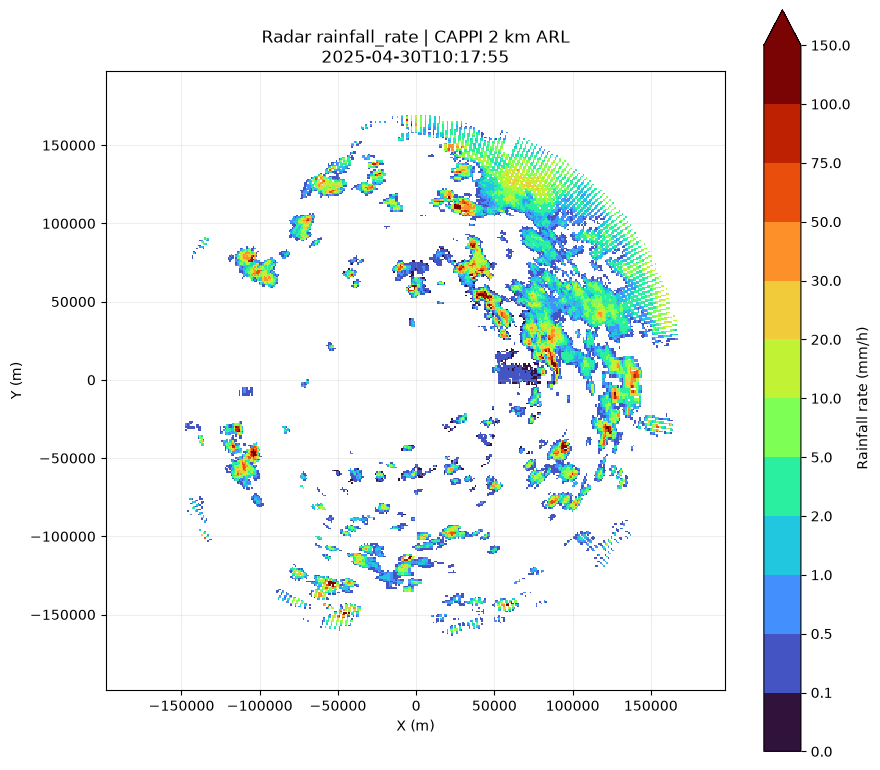

Valid pixels: 19,081 / 156,816
Spatial coverage: 12.2%
Rainfall rate range: 0.07 to 190.85 mm/h
Mean rainfall rate: 6.81 mm/h


In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

# Open first QPE NetCDF
nc_file = "/Users/matthewwright/Downloads/test_hdf_files/20250430_0600.nc"

with xr.open_dataset(nc_file) as ds:
    print(ds)

    # Select first timestep
    rainfall_rate = ds["rainfall_rate"].isel(time=0).load()

    # Rainfall rate thresholds (mm/h)
    levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150]

    cmap = plt.get_cmap("turbo", len(levels) - 1)
    norm = BoundaryNorm(levels, cmap.N)

    fig, ax = plt.subplots(figsize=(9, 8))

    rainfall_rate.plot(
        ax=ax,
        x="x",
        y="y",
        cmap=cmap,
        norm=norm,
        cbar_kwargs={
            "label": "Rainfall rate (mm/h)",
            "ticks": levels,
            "extend": "max"
        }
    )

    ax.set_title(
        f"Radar rainfall_rate | CAPPI {CAPPI_HEIGHT_ARL_M/1000:g} km ARL\n"
        f"{str(rainfall_rate.time.values)[:19]}"
    )
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    # Coverage and rainfall statistics
    valid = np.isfinite(rainfall_rate.values)

    print(f"Valid pixels: {valid.sum():,} / {valid.size:,}")
    print(f"Spatial coverage: {100 * valid.mean():.1f}%")

    if valid.any():
        print(f"Rainfall rate range: "
              f"{np.nanmin(rainfall_rate.values):.2f} to "
              f"{np.nanmax(rainfall_rate.values):.2f} mm/h")
        print(f"Mean rainfall rate: "
              f"{np.nanmean(rainfall_rate.values):.2f} mm/h")

In [33]:
with xr.open_dataset(REFERENCE_NC) as ref, \
     xr.open_dataset(nc_file) as qpe:

    for coord in ["x", "y", "lat", "lon"]:
        match = np.allclose(
            ref[coord].values,
            qpe[coord].values,
            equal_nan=True
        )
        print(f"{coord}: {'MATCH' if match else 'MISMATCH'}")

x: MATCH
y: MATCH
lat: MATCH
lon: MATCH


In [42]:
#After testing full python script, plots bhelow

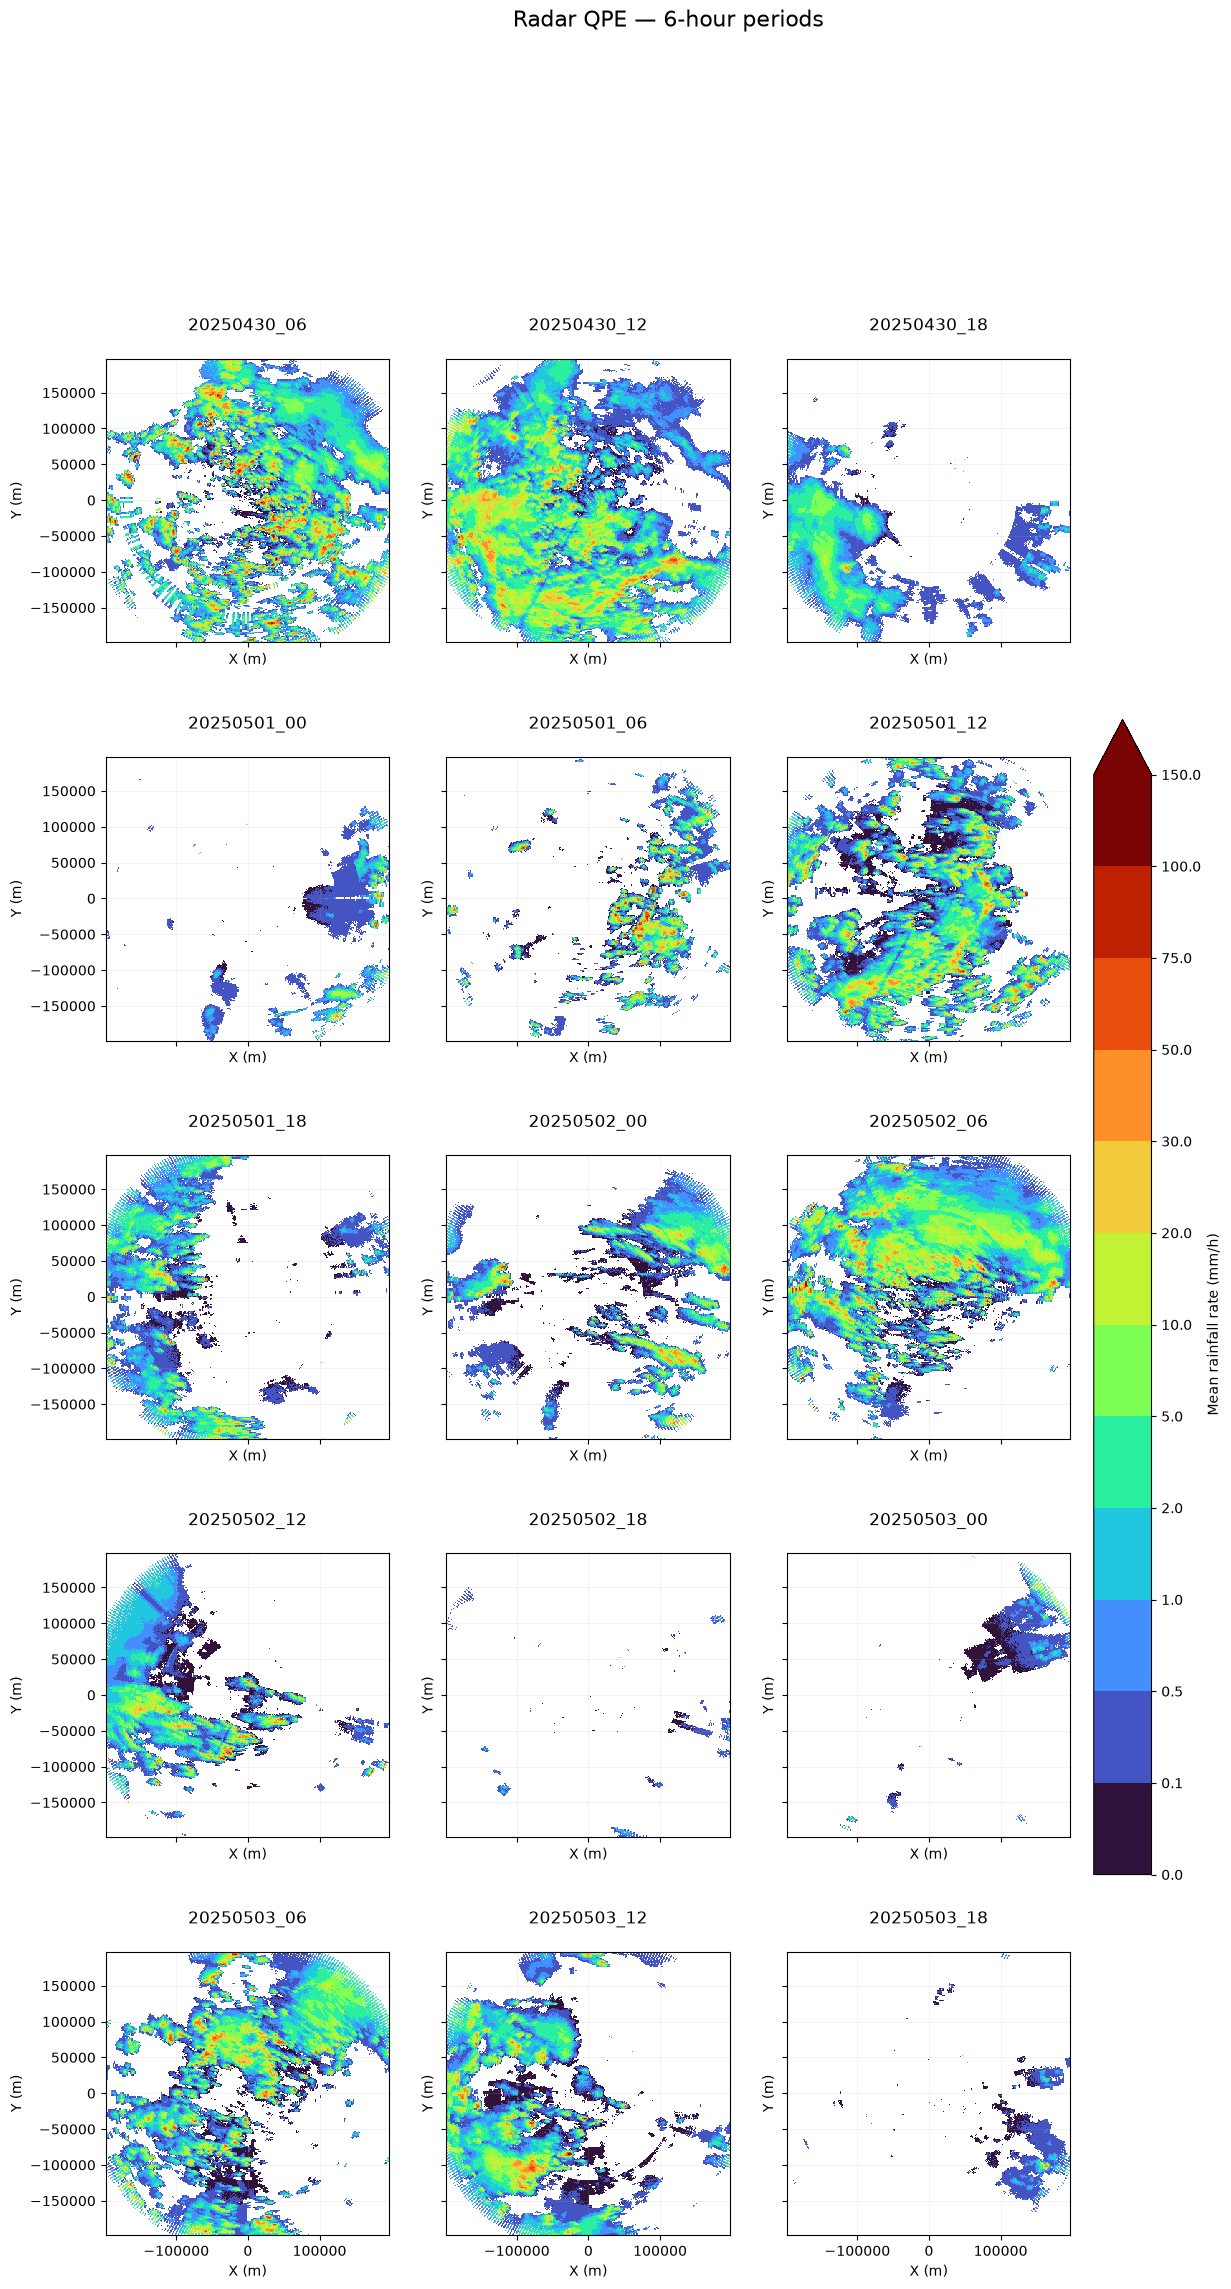

In [50]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import xarray as xr
import math

OUTPUT_DIR = Path('/Users/matthewwright/Downloads/test_hdf_files_simple')

nc_files = sorted(OUTPUT_DIR.glob("*.nc"))
assert nc_files, "No NetCDF files found"

# Plot settings
levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150]
cmap = plt.get_cmap("turbo", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

ncols = 3
nrows = math.ceil(len(nc_files) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 5 * nrows),
    squeeze=False,
    sharex=True,
    sharey=True
)

for ax, nc_file in zip(axes.flat, nc_files):
    with xr.open_dataset(nc_file) as ds:
        # Mean rainfall rate over the 6-hour window
        rainfall = ds["rainfall_rate"].load()

        rainfall.plot(
            ax=ax,
            x="x",
            y="y",
            cmap=cmap,
            norm=norm,
            add_colorbar=False
        )

        ax.set_title(
            f"{nc_file.stem}\n"
            # f"{ds.sizes['time']} timesteps"
        )
        ax.set_aspect("equal")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.grid(alpha=0.15)

# Hide unused panels
for ax in axes.flat[len(nc_files):]:
    ax.axis("off")

# Shared colourbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    label="Mean rainfall rate (mm/h)",
    ticks=levels,
    extend="max",
    shrink=0.6,
    pad=0.02
)

fig.suptitle(
    "Radar QPE — 6-hour periods",
    fontsize=16,
    y=1.01
)

plt.show()

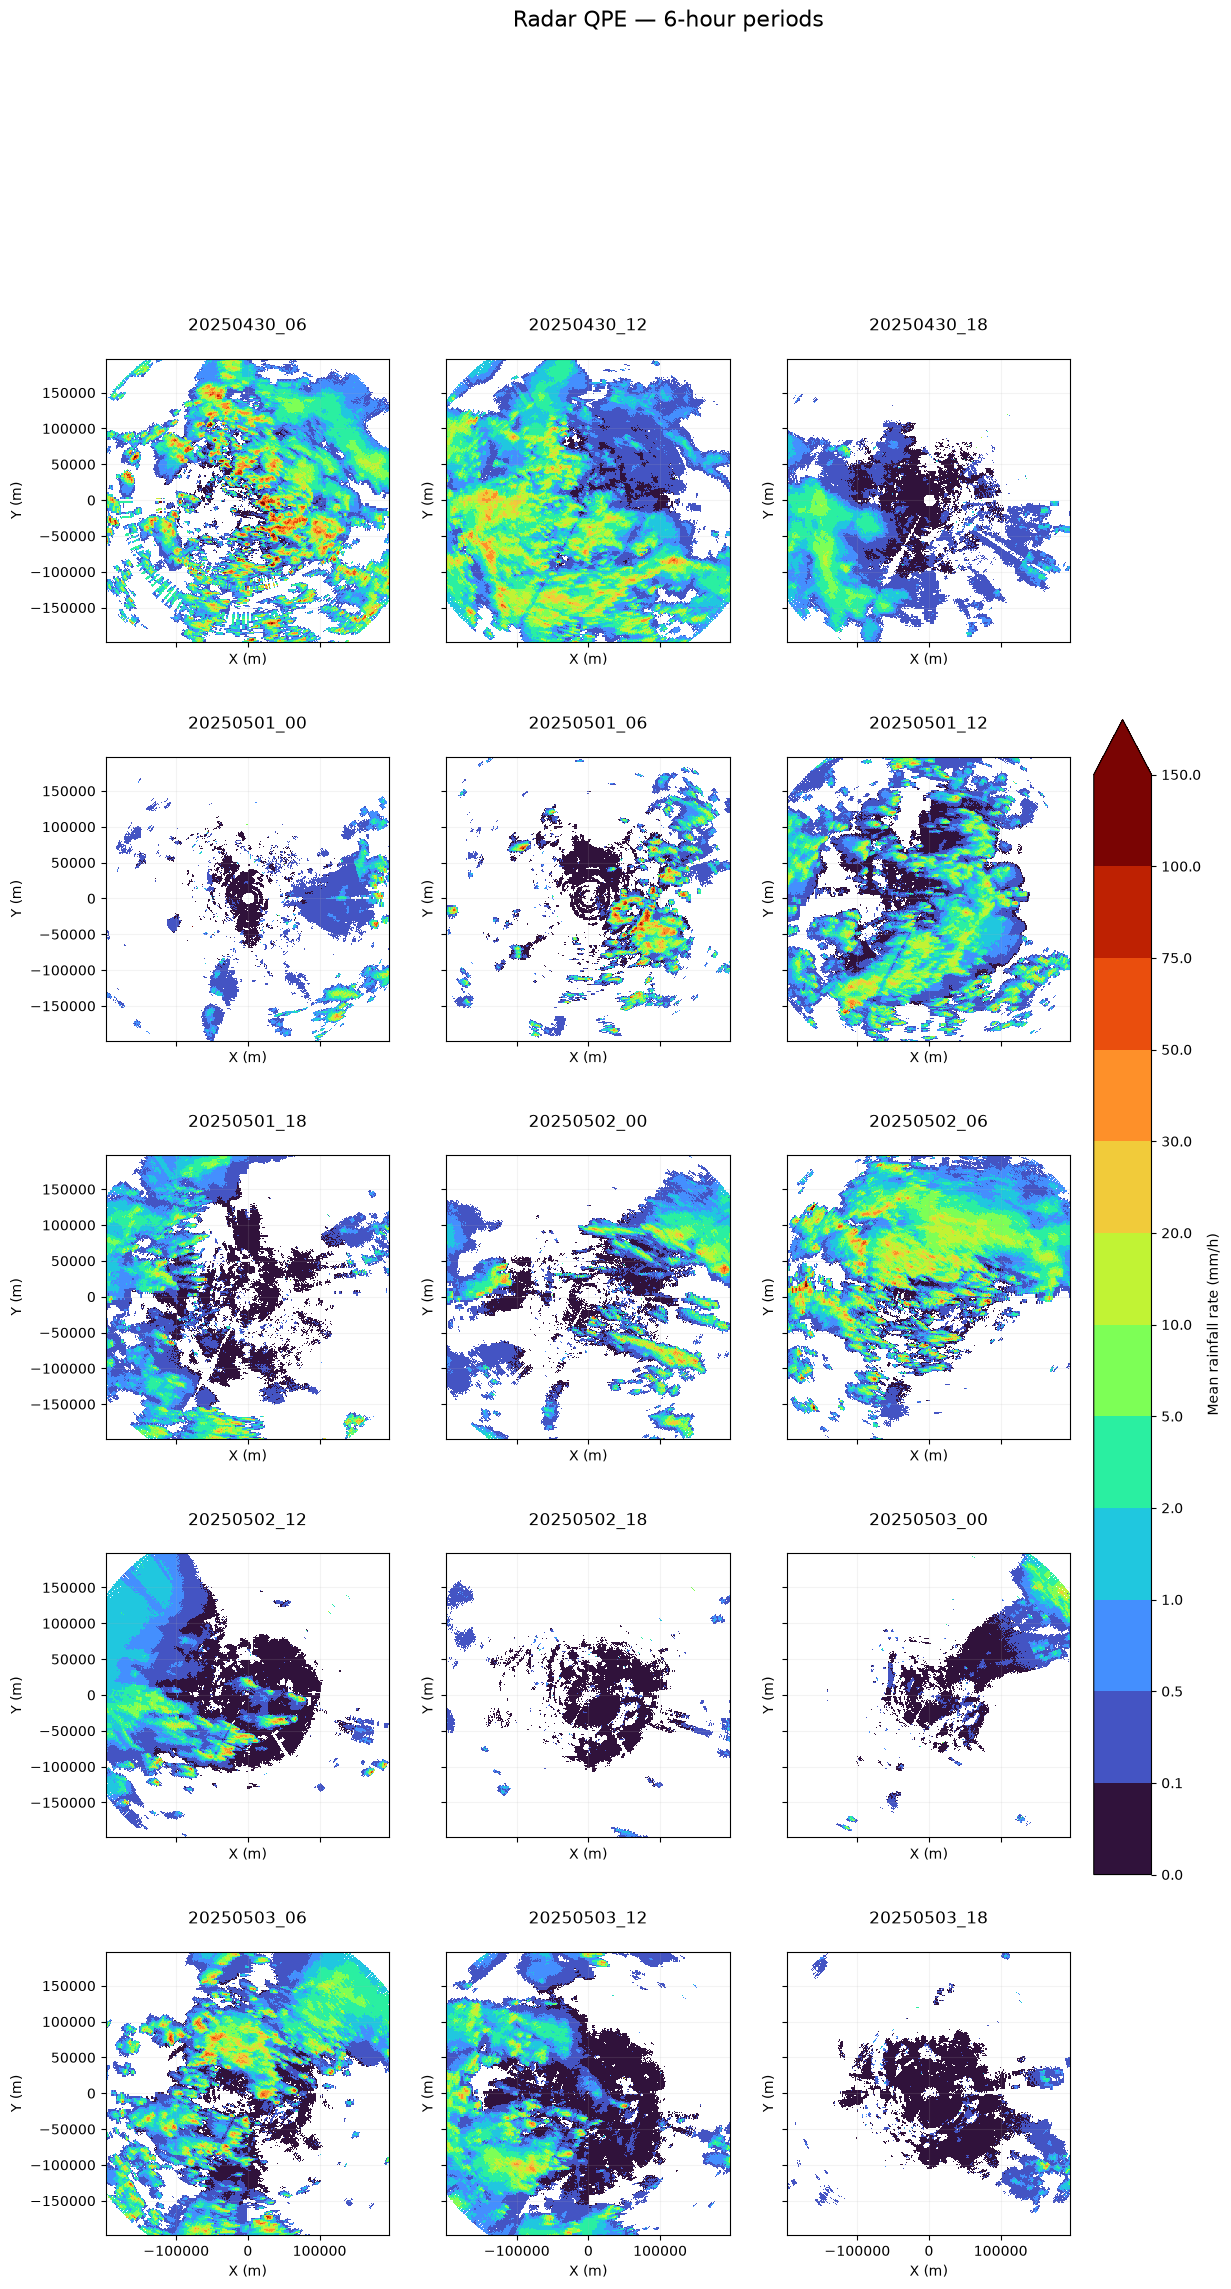

In [51]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import xarray as xr
import math

OUTPUT_DIR = Path('/Users/matthewwright/Downloads/test_hdf_files_cmax')

nc_files = sorted(OUTPUT_DIR.glob("*.nc"))
assert nc_files, "No NetCDF files found"

# Plot settings
levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150]
cmap = plt.get_cmap("turbo", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

ncols = 3
nrows = math.ceil(len(nc_files) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 5 * nrows),
    squeeze=False,
    sharex=True,
    sharey=True
)

for ax, nc_file in zip(axes.flat, nc_files):
    with xr.open_dataset(nc_file) as ds:
        # Mean rainfall rate over the 6-hour window
        rainfall = ds["rainfall_rate"].load()

        rainfall.plot(
            ax=ax,
            x="x",
            y="y",
            cmap=cmap,
            norm=norm,
            add_colorbar=False
        )

        ax.set_title(
            f"{nc_file.stem}\n"
            # f"{ds.sizes['time']} timesteps"
        )
        ax.set_aspect("equal")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.grid(alpha=0.15)

# Hide unused panels
for ax in axes.flat[len(nc_files):]:
    ax.axis("off")

# Shared colourbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    label="Mean rainfall rate (mm/h)",
    ticks=levels,
    extend="max",
    shrink=0.6,
    pad=0.02
)

fig.suptitle(
    "Radar QPE — 6-hour periods",
    fontsize=16,
    y=1.01
)

plt.show()

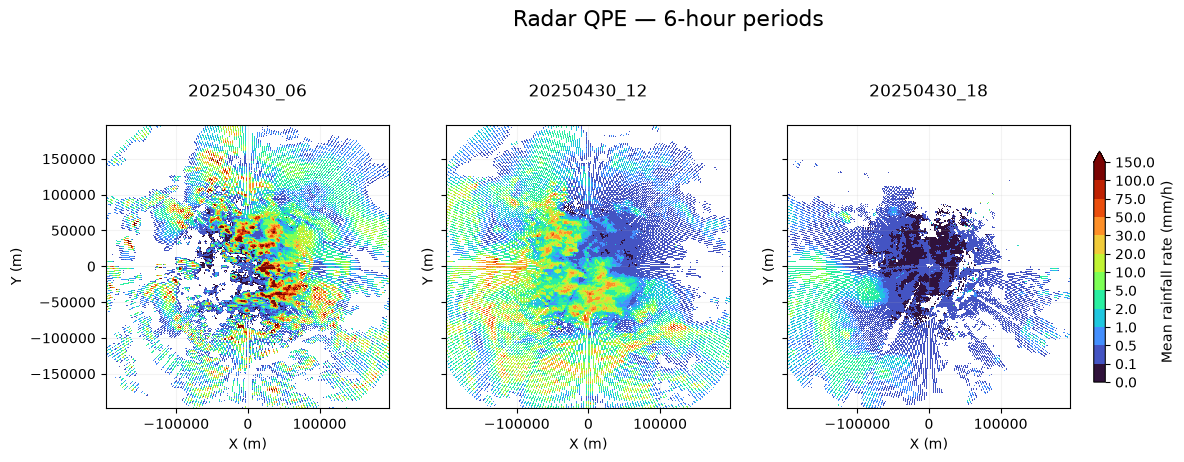

In [55]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import numpy as np
import xarray as xr
import math

OUTPUT_DIR = Path('/Users/matthewwright/Downloads/test_hdf_files_cmax_nopyart')

nc_files = sorted(OUTPUT_DIR.glob("*.nc"))
assert nc_files, "No NetCDF files found"

# Plot settings
levels = [0, 0.1, 0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150]
cmap = plt.get_cmap("turbo", len(levels) - 1)
norm = BoundaryNorm(levels, cmap.N)

ncols = 3
nrows = math.ceil(len(nc_files) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 5 * nrows),
    squeeze=False,
    sharex=True,
    sharey=True
)

for ax, nc_file in zip(axes.flat, nc_files):
    with xr.open_dataset(nc_file) as ds:
        # Mean rainfall rate over the 6-hour window
        rainfall = ds["rainfall_rate"].load()

        rainfall.plot(
            ax=ax,
            x="x",
            y="y",
            cmap=cmap,
            norm=norm,
            add_colorbar=False
        )

        ax.set_title(
            f"{nc_file.stem}\n"
            # f"{ds.sizes['time']} timesteps"
        )
        ax.set_aspect("equal")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.grid(alpha=0.15)

# Hide unused panels
for ax in axes.flat[len(nc_files):]:
    ax.axis("off")

# Shared colourbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    label="Mean rainfall rate (mm/h)",
    ticks=levels,
    extend="max",
    shrink=0.6,
    pad=0.02
)

fig.suptitle(
    "Radar QPE — 6-hour periods",
    fontsize=16,
    y=1.01
)

plt.show()